<!-- m6:clase=6;checkpoints=7;preguntas=3 -->
# Módulo 6 · Clase 6 — Series con LSTM · Riesgo de crédito · RAG y agentes con MCP · DevSecOps y tableros
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · miércoles 18-11-2026 · 18:30–21:30

**Cómo trabajar este cuaderno**
1. Ejecute las celdas en orden con `Shift + Enter`. Las celdas **➕ Ejemplo adicional** son opcionales.
2. En cada **✏️ Checkpoint** complete los `___` y ejecute: si está bien, aparece ✅ y un código personal.
3. Responda las **💬 Preguntas** en 2 o 3 líneas.
4. Al final: **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta `talleres/clase6.ipynb` → mensaje `Clase 6`.

> Datos simulados de la app **PagoYa** (ficticia). Es la última clase con contenido: la Clase 7 es solo para las presentaciones del proyecto.

## 0. Preparación y registro (Checkpoint 0)

In [1]:
import importlib, subprocess, sys
for paquete in ['shap', 'lightgbm', 'plotly']:                 # normalmente ya vienen en Colab
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
print('Paquetes listos')

Paquetes listos


In [2]:
import os, re, json, math, time, warnings, urllib.request
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore'); os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.feature_extraction.text import TfidfVectorizer
import lightgbm as lgb, shap
plt.rcParams['figure.figsize'] = (10, 3.4)
print('Listo · curso', curso.VERSION, '· TensorFlow', tf.__version__)

Listo · curso m6-2026.11 · TensorFlow 2.21.0


### ✏️ Checkpoint 0 · ⏱ 2 min
Registre su nombre como **'Apellido Nombre'** e indique la **clase 6**.

In [3]:
curso.registrar('Villamarin Kevin', clase=6)          # ✏️ su apellido y nombre, y el número de esta clase

Estudiante registrado: Villamarin Kevin
Clase 6
✅ Checkpoint 0 correcto · código K0-389B


---
## 6.1 Series de tiempo con LSTM (sin fuga de datos)
Una **LSTM** es una red recurrente con «memoria»: lee una **ventana** de días pasados y predice el siguiente. Reglas para no hacer trampa:
1. La prueba son los **últimos 90 días** (nunca se mezclan fechas).
2. Cada ventana usa **solo el pasado**; la escala se calcula **solo con entrenamiento**.
3. Siempre se compara contra un **benchmark ingenuo** (el mismo día de la semana anterior), como en el Módulo 5.

Serie diaria: 1096 días (2023-11-01 a 2026-10-31)


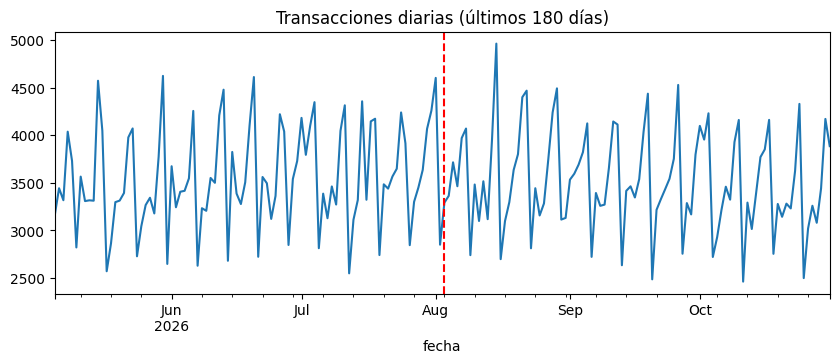

In [4]:
serie = curso.serie_transacciones()
y = serie['transacciones'].values.astype(float)
H = 90                                                      # horizonte de prueba: últimos 90 días
fechas_prueba = serie['fecha'].values[-H:]
serie.set_index('fecha')['transacciones'].iloc[-180:].plot(title='Transacciones diarias (últimos 180 días)'); plt.axvline(serie['fecha'].iloc[-H], color='red', ls='--'); plt.show()

### ✏️ Checkpoint 1 · ⏱ 4 min
Complete la función que arma **ventanas** de W = 28 días (X) y el valor del día siguiente (Y). ¿Cuántas ventanas salen de la serie completa?

In [5]:
def ventanas(valores, W):
    X = np.array([valores[i:i + 28] for i in range(len(valores) - W)])   # ✏️ W días seguidos
    Y = np.array([valores[i + 1] for i in range(len(valores) - W)])     # ✏️ el día siguiente
    return X, Y
W = 28
X_todo, Y_todo = ventanas(np.log(y), W)
print('Ventanas:', X_todo.shape)
curso.checkpoint(1, X_todo.shape[0])

Ventanas: (1068, 28)
✅ Checkpoint 1 correcto · código K1-66C5


### ✏️ Checkpoint 2 · ⏱ 3 min
Calcule el **MAE del benchmark ingenuo estacional**: predecir cada día de prueba con el valor de **7 días antes**.

In [6]:
real = y[-H:]
ingenuo = y[-H - 7:-7]                                       # ✏️ el mismo día de la semana anterior
mae_ingenuo = np.mean(np.abs(real - ingenuo))
print(f'MAE ingenuo (t − 7): {mae_ingenuo:.2f} transacciones/día')
curso.checkpoint(2, mae_ingenuo)

MAE ingenuo (t − 7): 236.77 transacciones/día
✅ Checkpoint 2 correcto · código K2-A23A


### Entrenar la LSTM
Truco para series con tendencia: cada ventana se expresa **relativa a su propia media** (en logaritmos). Así la red aprende la **forma** (semana, quincena) y no el nivel, que crece con el tiempo.

In [7]:
base = X_todo.mean(axis=1)                                  # nivel de cada ventana (solo pasado)
X_rel, Y_rel = X_todo - base[:, None], Y_todo - base
n_ent = len(y) - H - W                                      # ventanas cuyo día objetivo está en entrenamiento
escala = X_rel[:n_ent].std()                                # escala calculada SOLO con entrenamiento
X_ent, Y_ent = X_rel[:n_ent, :, None] / escala, Y_rel[:n_ent] / escala
X_pru = X_rel[n_ent:, :, None] / escala

keras.utils.set_random_seed(42)
lstm = keras.Sequential([keras.Input(shape=(W, 1)), keras.layers.LSTM(32), keras.layers.Dense(1)])
lstm.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
t0 = time.perf_counter()
h = lstm.fit(X_ent, Y_ent, validation_split=0.15, epochs=80, batch_size=32, verbose=0,
             callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])
pred_lstm = np.exp(lstm.predict(X_pru, verbose=0).ravel() * escala + base[n_ent:])
lineal = LinearRegression().fit(X_rel[:n_ent], Y_rel[:n_ent])        # regresión lineal sobre los mismos rezagos
pred_lineal = np.exp(lineal.predict(X_rel[n_ent:]) + base[n_ent:])
mae = lambda p: np.mean(np.abs(real - p))
tabla_series = pd.DataFrame({'modelo': ['Ingenuo (t − 7)', 'Regresión lineal (28 rezagos)', 'LSTM (32 unidades)'],
                             'MAE': [mae(ingenuo), mae(pred_lineal), mae(pred_lstm)]}).round(1)
tabla_series['mejora vs ingenuo'] = (1 - tabla_series['MAE'] / tabla_series['MAE'].iloc[0]).map('{:.0%}'.format)
print(f'Épocas: {len(h.history["loss"])} · {time.perf_counter() - t0:.0f} s'); tabla_series

Épocas: 80 · 21 s


,modelo,MAE,mejora vs ingenuo
0,Ingenuo (t − 7),236.8,0%
1,Regresión lineal (28 rezagos),568.0,-140%
2,LSTM (32 unidades),465.7,-97%


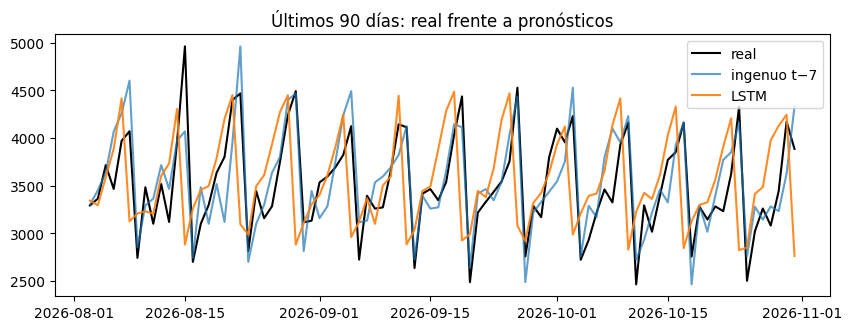

In [8]:
plt.plot(fechas_prueba, real, label='real', color='black', lw=1.5)
plt.plot(fechas_prueba, ingenuo, label='ingenuo t−7', alpha=0.7); plt.plot(fechas_prueba, pred_lstm, label='LSTM', alpha=0.9)
plt.legend(); plt.title('Últimos 90 días: real frente a pronósticos'); plt.show()

### ➕ Ejemplo adicional: ¿dónde se equivoca? Error por día de la semana

In [9]:
err = pd.DataFrame({'dia': pd.to_datetime(fechas_prueba).day_name(), 'ingenuo': np.abs(real - ingenuo), 'LSTM': np.abs(real - pred_lstm)})
err.groupby('dia')[['ingenuo', 'LSTM']].mean().round(0)

,ingenuo,LSTM
dia,,
Friday,240.0,364.0
Monday,214.0,169.0
Saturday,286.0,1377.0
Sunday,192.0,387.0
Thursday,340.0,479.0
Tuesday,179.0,185.0
Wednesday,202.0,292.0


### 💬 Pregunta 1
La LSTM mejoró al benchmark ingenuo, pero la regresión lineal quedó cerca. En una institución, ¿cuándo justificaría usar una LSTM en lugar de ARIMA o una regresión con rezagos?

**Respuesta:**

* Cuando existe no linealidad compleja que la regresión no captura
* Cuando el margen de mejora tiene un alto valor económico
* Cuando se dispone de gran volumen de datos y alta dimensionalidad

---
## 6.2 Riesgo financiero: scoring de crédito, KS, decisión y equidad
Métricas de la industria de crédito:
- **AUC** y **Gini = 2·AUC − 1** (capacidad de ordenar).
- **KS** (Kolmogorov-Smirnov): máxima distancia entre las distribuciones del puntaje de buenos y malos = máx(TPR − FPR).
- **Tabla de deciles (lift)**: tasa de default por decil de riesgo.

In [10]:
cred = curso.creditos_clase6()
X = pd.get_dummies(cred.drop(columns=['solicitud_id', 'default', 'sexo']), columns=['tipo_empleo'], drop_first=True).astype(float)
y_c = cred['default']                                       # 'sexo' NO entra al modelo: solo se usa para auditar equidad
Xc_ent, Xc_pru, yc_ent, yc_pru = train_test_split(X, y_c, test_size=0.3, stratify=y_c, random_state=42)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xc_ent, yc_ent)
p_log = logit.predict_proba(Xc_pru)[:, 1]
print(f'AUC logística: {roc_auc_score(yc_pru, p_log):.3f} · Gini: {2 * roc_auc_score(yc_pru, p_log) - 1:.3f}')

Solicitudes: 4000 · tasa de default 12.47%
AUC logística: 0.767 · Gini: 0.534


### ✏️ Checkpoint 3 · ⏱ 4 min
Calcule el **KS** de la logística en prueba como el máximo de **TPR − FPR** de la curva ROC.

In [12]:
fpr, tpr, umbrales = roc_curve(yc_pru, p_log)
ks = np.max(tpr - fpr)                                       # ✏️ máxima separación
print(f'KS = {ks:.3f} en el umbral {umbrales[np.argmax(tpr - fpr)]:.3f}')
curso.checkpoint(3, ks)

KS = 0.448 en el umbral 0.153
✅ Checkpoint 3 correcto · código K3-00B4


,AUC,Gini,KS
Logística,0.767,0.534,0.448
LightGBM,0.753,0.506,0.410


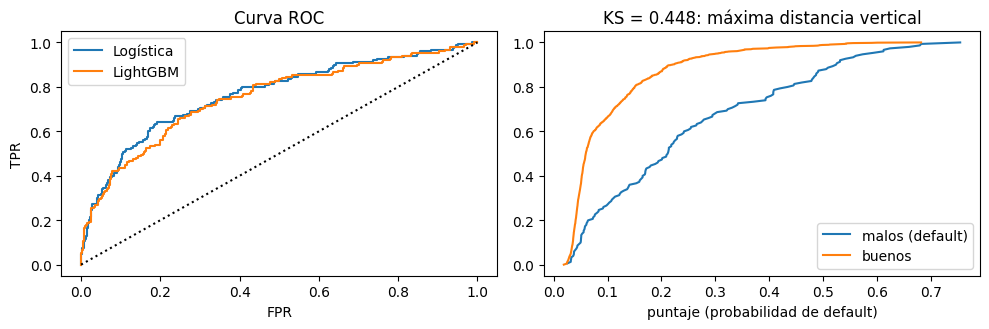

In [13]:
gbm = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, random_state=42, verbose=-1).fit(Xc_ent, yc_ent)
p_gbm = gbm.predict_proba(Xc_pru)[:, 1]
def metricas(p):
    f, t, _ = roc_curve(yc_pru, p); a = roc_auc_score(yc_pru, p)
    return {'AUC': round(a, 3), 'Gini': round(2 * a - 1, 3), 'KS': round(np.max(t - f), 3)}
display(pd.DataFrame({'Logística': metricas(p_log), 'LightGBM': metricas(p_gbm)}).T)
fig, ax = plt.subplots(1, 2)
for nombre, p in [('Logística', p_log), ('LightGBM', p_gbm)]:
    f, t, _ = roc_curve(yc_pru, p); ax[0].plot(f, t, label=nombre)
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].set_title('Curva ROC'); ax[0].legend()
malos, buenos = np.sort(p_log[yc_pru == 1]), np.sort(p_log[yc_pru == 0])
ax[1].plot(malos, np.arange(1, len(malos) + 1) / len(malos), label='malos (default)')
ax[1].plot(buenos, np.arange(1, len(buenos) + 1) / len(buenos), label='buenos')
ax[1].set_title(f'KS = {ks:.3f}: máxima distancia vertical'); ax[1].set_xlabel('puntaje (probabilidad de default)'); ax[1].legend()
plt.tight_layout(); plt.show()

In [14]:
deciles = pd.DataFrame({'p': p_log, 'default': yc_pru.values})
deciles['decil de riesgo'] = pd.qcut(deciles['p'], 10, labels=range(10, 0, -1))   # 1 = más riesgoso
lift = deciles.groupby('decil de riesgo', observed=True).agg(solicitudes=('default', 'size'), tasa_default=('default', 'mean')).sort_index()
lift['lift'] = (lift['tasa_default'] / deciles['default'].mean()).round(2)
lift.round(3)

,solicitudes,tasa_default,lift
decil de riesgo,,,
10,120,0.042,0.33
9,120,0.042,0.33
8,120,0.033,0.27
7,120,0.058,0.47
6,120,0.075,0.60
5,120,0.075,0.60
4,120,0.092,0.73
3,120,0.142,1.13
2,120,0.242,1.93


### Decisión: ¿hasta qué probabilidad aprobamos?
Supuesto del proyecto: un **default pierde el monto**; un **buen pagador deja 15 % del monto**. Se aprueba si la probabilidad de default es menor que el umbral.

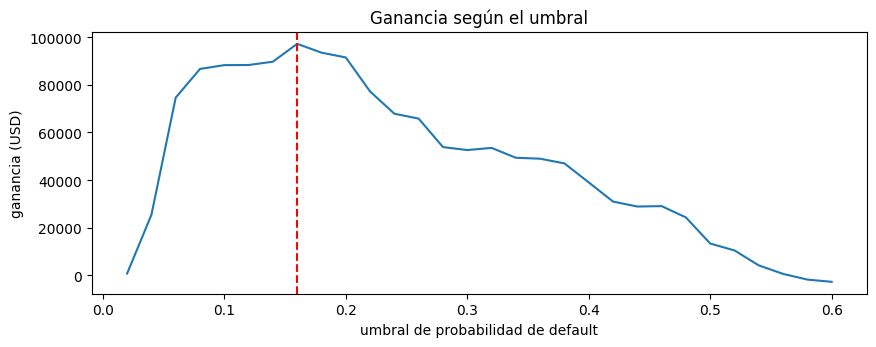

Umbral óptimo 0.16 · aprueba 76% · ganancia USD 97,212 (aprobar a todos: USD -13,864)


In [15]:
monto = cred.loc[Xc_pru.index, 'monto_credito'].values
resultado = []
for u in np.arange(0.02, 0.62, 0.02):
    aprobar = p_log < u
    ganancia = np.sum((0.15 * monto * (yc_pru.values == 0) - monto * (yc_pru.values == 1))[aprobar])
    resultado.append({'umbral': round(u, 2), 'aprobación': aprobar.mean(), 'ganancia': ganancia})
res = pd.DataFrame(resultado); mejor = res.loc[res['ganancia'].idxmax()]
plt.plot(res['umbral'], res['ganancia']); plt.axvline(mejor['umbral'], color='red', ls='--')
plt.xlabel('umbral de probabilidad de default'); plt.ylabel('ganancia (USD)'); plt.title('Ganancia según el umbral'); plt.show()
aprobar_todos = np.sum(0.15 * monto * (yc_pru.values == 0) - monto * (yc_pru.values == 1))
print(f"Umbral óptimo {mejor['umbral']:.2f} · aprueba {mejor['aprobación']:.0%} · ganancia USD {mejor['ganancia']:,.0f} (aprobar a todos: USD {aprobar_todos:,.0f})")

### Explicar un rechazo con SHAP
En crédito hay que poder decirle al cliente **por qué** se le negó. SHAP descompone la predicción de UNA solicitud en el aporte de cada variable.

Solicitud: CR-03886 · probabilidad de default 0.92


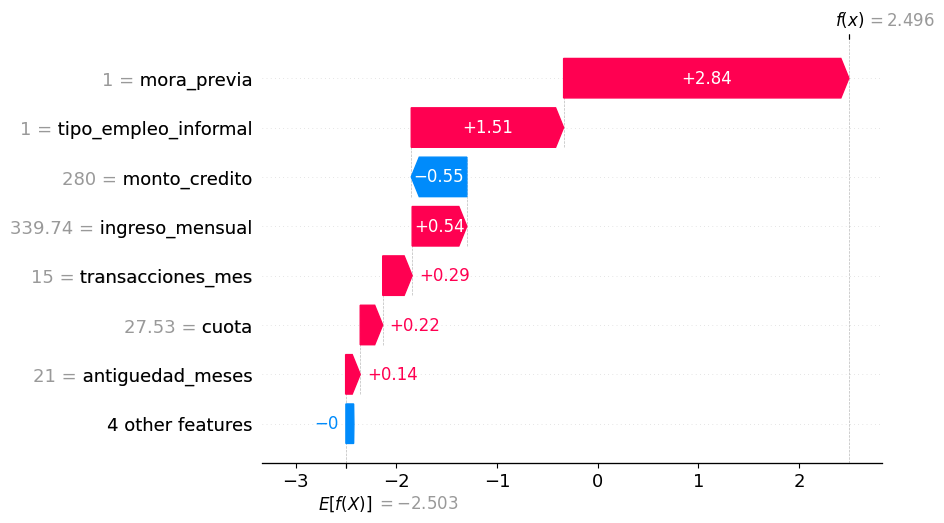

Principales motivos del rechazo: mora_previa, tipo_empleo_informal, ingreso_mensual


In [16]:
explicador = shap.TreeExplainer(gbm)
valores = explicador(Xc_pru)
i = int(np.argmax(p_gbm))                                   # la solicitud más riesgosa de la prueba
print('Solicitud:', cred.loc[Xc_pru.index[i], 'solicitud_id'], f'· probabilidad de default {p_gbm[i]:.2f}')
shap.plots.waterfall(valores[i], max_display=8)
motivos = pd.Series(valores[i].values, index=Xc_pru.columns).sort_values(ascending=False).head(3)
print('Principales motivos del rechazo:', ', '.join(motivos.index))

### Equidad: ¿el modelo aprueba distinto a hombres y mujeres?
`sexo` **no** está en el modelo, pero puede haber **proxies** (variables correlacionadas, como el ingreso). Se mide la **razón de impacto dispar**: tasa de aprobación del grupo protegido / tasa del grupo de referencia. Regla de los 4/5: preocupa si es **< 0,80**.

### ✏️ Checkpoint 4 · ⏱ 4 min
Con el umbral de **0,15**, calcule la tasa de aprobación por sexo y la **razón de impacto dispar F / M**.

In [17]:
aprobado = pd.Series(p_log < 0.15, index=Xc_pru.index)          # ✏️ umbral 0.15
tasas = aprobado.groupby(cred.loc[Xc_pru.index, 'sexo']).mean()
razon = tasas['F'] / tasas['M']                              # ✏️ grupo protegido / referencia
print(tasas.round(3).to_dict(), f'· razón de impacto dispar = {razon:.3f}')
curso.checkpoint(4, razon)

{'F': 0.735, 'M': 0.752} · razón de impacto dispar = 0.977
✅ Checkpoint 4 correcto · código K4-8EB2


In [18]:
por_empleo = aprobado.groupby(cred.loc[Xc_pru.index, 'tipo_empleo']).mean()
real_empleo = yc_pru.groupby(cred.loc[Xc_pru.index, 'tipo_empleo']).mean()
pd.DataFrame({'tasa de aprobación': por_empleo, 'default real': real_empleo,
              'razón vs dependiente': por_empleo / por_empleo['dependiente']}).round(3)

,tasa de aprobación,default real,razón vs dependiente
tipo_empleo,,,
dependiente,0.801,0.092,1.000
independiente,0.805,0.108,1.006
informal,0.498,0.236,0.622


### 💬 Pregunta 2
Su modelo de crédito tiene KS = 0,45 y una razón de impacto dispar de 0,65 para un grupo. ¿El modelo está listo para producción? ¿Qué haría antes de aprobarlo?

**Respuesta:**

No, no está listo para producción.
Aunque el KS (0.45) indica una buena capacidad predictiva, una razón de impacto dispar de 0.65 viola la "regla del 80%" (umbral mínimo estándar de 0.80), lo que evidencia un sesgo discriminatorio inaceptable contra ese grupo.

---
## 6.3 IA generativa en la práctica: RAG mínimo y un agente con MCP
Construimos las piezas **sin un LLM de pago**, para ver cómo funcionan por dentro:
1. **RAG**: recuperar el documento correcto de las políticas de PagoYa y **citarlo**.
2. **MCP**: un servidor que expone **herramientas** con mensajes JSON-RPC, valida la identidad y registra auditoría.
3. Un **agente** que decide qué herramienta usar (en producción esa decisión la toma el LLM con *function calling*).

In [19]:
politicas = pd.DataFrame(curso.POLITICAS)
vectorizador = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), strip_accents='unicode', lowercase=True)   # trozos de 3 a 5 letras
matriz = vectorizador.fit_transform(politicas['titulo'] + '. ' + politicas['texto'])
def buscar(pregunta, k=2):
    sim = (matriz @ vectorizador.transform([pregunta]).T).toarray().ravel()   # similitud coseno (TF-IDF normalizado)
    orden = np.argsort(-sim)[:k]
    return politicas.iloc[orden].assign(similitud=sim[orden].round(3))[['id', 'titulo', 'similitud']]
politicas[['id', 'titulo']]

,id,titulo
0,POL-01,Límites de transacción
1,POL-02,Bloqueo preventivo por fraude
2,POL-03,Requisitos del microcrédito
3,POL-04,Reclamos por transacciones no reconocidas
4,POL-05,Protección de datos personales
5,POL-06,Comisiones
6,POL-07,Dispositivo nuevo
7,POL-08,Atención al cliente


### ✏️ Checkpoint 5 · ⏱ 3 min
¿Qué política recupera el buscador para la pregunta del cliente? Entregue el **id** del primer resultado.

In [20]:
pregunta = '¿Cuántos días tengo para reclamar una transacción que no reconozco?'
resultados = buscar(pregunta)                                 # ✏️ use la función de búsqueda
display(resultados)
curso.checkpoint(5, resultados['id'].iloc[0])

,id,titulo,similitud
3,POL-04,Reclamos por transacciones no reconocidas,0.548
1,POL-02,Bloqueo preventivo por fraude,0.215


✅ Checkpoint 5 correcto · código K5-0FE4


In [21]:
def responder(pregunta, minimo=0.20):
    r = buscar(pregunta, k=1).iloc[0]
    if r['similitud'] < minimo:                                # sin soporte suficiente: no inventar
        return 'No encuentro esa información en las políticas de PagoYa. Le comunico con un asesor.'
    texto = politicas.set_index('id').loc[r['id'], 'texto']
    return f"{texto} [Fuente: {r['id']} · {r['titulo']}]"     # en producción, un LLM redacta usando SOLO este texto
for q in ['¿Cuántos días tengo para reclamar una transacción que no reconozco?', '¿Cuánto cuesta retirar en un agente?',
          '¿Me recomiendan invertir en criptomonedas?']:
    print('❓', q, '\n💬', responder(q), '\n')

❓ ¿Cuántos días tengo para reclamar una transacción que no reconozco? 
💬 El cliente tiene 30 días desde la fecha de la transacción para presentar un reclamo por una transacción no reconocida. La respuesta se entrega en un máximo de 15 días hábiles y, si procede, el dinero se acredita en la cuenta. [Fuente: POL-04 · Reclamos por transacciones no reconocidas] 

❓ ¿Cuánto cuesta retirar en un agente? 
💬 Las transferencias entre usuarios de PagoYa no tienen comisión. Los retiros en agentes cuestan 0,50 dólares y las recargas de telefonía son gratuitas. [Fuente: POL-06 · Comisiones] 

❓ ¿Me recomiendan invertir en criptomonedas? 
💬 No encuentro esa información en las políticas de PagoYa. Le comunico con un asesor. 



### Un servidor MCP mínimo
MCP usa mensajes **JSON-RPC 2.0**. El cliente (la app con el LLM) pide `tools/list` para saber qué herramientas hay y `tools/call` para ejecutarlas. El servidor valida la **identidad del usuario autenticado** (no la que diga el modelo) y deja **auditoría**.

In [22]:
perfiles = curso._perfiles_usuarios(curso.cargar_pagoya_limpio()).set_index('usuario_id')
servidor = curso.ServidorMCP('pagoya')

@servidor.herramienta('Resumen de la actividad del usuario autenticado', {'usuario_id': {'type': 'string'}})
def consultar_perfil(usuario_id):
    p = perfiles.loc[usuario_id]
    return {'usuario_id': usuario_id, 'n_transacciones': int(p['n_transacciones']), 'monto_medio': float(p['monto_medio'])}

@servidor.herramienta('Busca en las políticas de PagoYa y cita la fuente', {'pregunta': {'type': 'string'}})
def buscar_politica(pregunta):
    return {'respuesta': responder(pregunta)}

print(json.dumps(servidor.atender({'jsonrpc': '2.0', 'id': 1, 'method': 'tools/list'}, usuario='U0002'), indent=1, ensure_ascii=False)[:900])

Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 8.44%
{
 "jsonrpc": "2.0",
 "id": 1,
 "result": {
  "tools": [
   {
    "name": "consultar_perfil",
    "description": "Resumen de la actividad del usuario autenticado",
    "inputSchema": {
     "type": "object",
     "properties": {
      "usuario_id": {
       "type": "string"
      }
     },
     "required": [
      "usuario_id"
     ]
    }
   },
   {
    "name": "buscar_politica",
    "description": "Busca en las políticas de PagoYa y cita la fuente",
    "inputSchema": {
     "type": "object",
     "properties": {
      "pregunta": {
       "type": "string"
      }
     },
     "required": [
      "pregunta"
     ]
    }
   }
  ]
 }
}


### ✏️ Checkpoint 6 · ⏱ 4 min
Escriba el mensaje JSON-RPC para llamar a la herramienta **consultar_perfil** del usuario autenticado **U0002** y obtenga su número de transacciones.

In [23]:
mensaje = {'jsonrpc': '2.0', 'id': 2, 'method': 'tools/call',                        # ✏️ método para ejecutar una herramienta
           'params': {'name': 'consultar_perfil', 'arguments': {'usuario_id': 'U0002'}}}   # ✏️ nombre de la herramienta
respuesta = servidor.atender(mensaje, usuario='U0002')
datos = json.loads(respuesta['result']['content'][0]['text'])
print(datos)
curso.checkpoint(6, datos['n_transacciones'])

{'usuario_id': 'U0002', 'n_transacciones': 4, 'monto_medio': 20.76}
✅ Checkpoint 6 correcto · código K6-FBC9


In [24]:
ataque = {'jsonrpc': '2.0', 'id': 3, 'method': 'tools/call', 'params': {'name': 'consultar_perfil', 'arguments': {'usuario_id': 'U0003'}}}
print('U0002 pide los datos de U0003 →', servidor.atender(ataque, usuario='U0002')['error'])
pd.DataFrame(servidor.auditoria)

U0002 pide los datos de U0003 → {'code': -32001, 'message': 'Permiso denegado: solo puede consultar sus propios datos'}


,usuario,herramienta,argumentos
0,U0002,consultar_perfil,{'usuario_id': 'U0002'}
1,U0002,consultar_perfil,{'usuario_id': 'U0003'}


### El agente: decide qué herramienta usar

In [25]:
def agente(pregunta, usuario):
    # En producción, el LLM recibe la lista de herramientas (tools/list) y devuelve la llamada estructurada.
    # Aquí una regla simple simula esa decisión.
    q = pregunta.lower()
    if re.search(r'\bmis?\b', q) and re.search(r'transacci|movimiento|actividad|cuenta', q):
        llamada = {'name': 'consultar_perfil', 'arguments': {'usuario_id': usuario}}
    else:
        llamada = {'name': 'buscar_politica', 'arguments': {'pregunta': pregunta}}
    r = servidor.atender({'jsonrpc': '2.0', 'id': 99, 'method': 'tools/call', 'params': llamada}, usuario=usuario)
    return llamada['name'], json.loads(r['result']['content'][0]['text'])
for q in ['¿Cuántas transacciones he hecho en mi cuenta?', '¿Qué pasa si inicio sesión en un celular nuevo?']:
    print('❓', q, '\n🔧', *agente(q, 'U0002'), '\n')

❓ ¿Cuántas transacciones he hecho en mi cuenta? 
🔧 consultar_perfil {'usuario_id': 'U0002', 'n_transacciones': 4, 'monto_medio': 20.76} 

❓ ¿Qué pasa si inicio sesión en un celular nuevo? 
🔧 buscar_politica {'respuesta': 'Al iniciar sesión desde un dispositivo nuevo, la app pide verificación biométrica y limita las transferencias a 200 dólares durante las primeras 24 horas. [Fuente: POL-07 · Dispositivo nuevo]'} 



### ➕ Ejemplo adicional: el mismo servidor con la librería oficial (FastMCP)

In [26]:
try:
    if importlib.util.find_spec('fastmcp') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'fastmcp'], timeout=120)
    from fastmcp import FastMCP, Client
    mcp = FastMCP('pagoya')
    @mcp.tool()
    def politica(pregunta: str) -> str:
        """Busca en las políticas de PagoYa y cita la fuente."""
        return responder(pregunta)
    async def demo():
        async with Client(mcp) as cliente:                  # cliente y servidor en memoria
            herramientas = await cliente.list_tools()
            r = await cliente.call_tool('politica', {'pregunta': '¿Cuánto cuesta retirar en un agente?'})
            return [h.name for h in herramientas], r
    nombres, r = await demo()
    print('Herramientas:', nombres); print('Respuesta:', getattr(r, 'data', r))
except Exception as e:
    print('FastMCP no disponible en este entorno:', type(e).__name__)

FastMCP no disponible en este entorno: ImportError


### 💬 Pregunta 3
¿Por qué el servidor MCP valida el usuario autenticado en lugar de confiar en el `usuario_id` que pide el modelo? Si su proyecto usara una clave de API (por ejemplo de un LLM), ¿cómo la manejaría para que no quede expuesta en GitHub?

**Respuesta:**

Esto se debe a un principio fundamental de seguridad llamado Confianza Cero (Zero Trust) aplicado a sistemas de IA. En esta arquitectura, el LLM (el modelo) se considera un componente "no confiable", mientras que el servidor MCP es la capa de datos "confiable".

---
## 6.4 DevSecOps y visualización
**Secretos**: nunca en el código. **Dependencias**: versiones fijas y auditadas. **Integración continua**: GitHub Actions ejecuta el verificador y las pruebas en cada commit. **Tablero**: los resultados se comunican con gráficos interactivos.

In [27]:
codigo_ejemplo = '''
API_KEY = "sk-live-9f8A7b6C5d4E3f2G1h0IjKlMnOpQrStUv"      # ❌ clave en el código
password = "Banco2026!"                                      # ❌ contraseña en texto plano
clave = os.environ.get("LLM_API_KEY")                       # ✅ leída de una variable de entorno
'''
patrones = {'clave de API': r'sk-[A-Za-z0-9-]{20,}', 'contraseña': r'(?i)(password|contrase[nñ]a)\s*=\s*["\'][^"\']+["\']'}
for n, linea in enumerate(codigo_ejemplo.strip().splitlines(), 1):
    for tipo, patron in patrones.items():
        if re.search(patron, linea):
            print(f'⚠️ línea {n}: posible {tipo} expuesta →', linea.split('#')[0].strip()[:45])

⚠️ línea 1: posible clave de API expuesta → API_KEY = "sk-live-9f8A7b6C5d4E3f2G1h0IjKlMnO
⚠️ línea 2: posible contraseña expuesta → password = "Banco2026!"


**Integración continua** (archivo `.github/workflows/verificar.yml` de su repositorio, simplificado):
```yaml
on: [push]                                   # se ejecuta en cada commit
jobs:
  verificar:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with: {python-version: '3.11'}
      - run: pip install -r requirements.txt pip-audit pytest
      - run: pip-audit -r requirements.txt   # auditoría de dependencias con vulnerabilidades conocidas
      - run: pytest -q                       # pruebas unitarias
      - run: python verificador.py           # verificador del curso
```

In [28]:
import plotly.graph_objects as go
fig = go.Figure()
fig.add_scatter(x=fechas_prueba, y=real, name='real', line=dict(color='black'))
fig.add_scatter(x=fechas_prueba, y=pred_lstm, name='LSTM')
fig.add_scatter(x=fechas_prueba, y=ingenuo, name='ingenuo t−7', line=dict(dash='dot'))
fig.update_layout(title='Pronóstico de transacciones diarias (interactivo)', height=380, hovermode='x unified')
fig.show()

In [29]:
%%writefile tablero.py
# Tablero mínimo con Streamlit: en su computador ejecute  →  streamlit run tablero.py
import streamlit as st, pandas as pd, plotly.express as px
st.set_page_config(page_title='PagoYa · Riesgo', layout='wide')
st.title('PagoYa · Tablero de riesgo')
umbral = st.slider('Umbral de aprobación (probabilidad de default)', 0.02, 0.60, 0.15)
df = pd.read_csv('scores.csv')                               # puntajes exportados desde el cuaderno
df['decision'] = (df['p'] < umbral).map({True: 'aprobar', False: 'rechazar'})
c1, c2 = st.columns(2)
c1.metric('Tasa de aprobación', f"{(df['decision'] == 'aprobar').mean():.0%}")
c2.metric('Default esperado en aprobados', f"{df.loc[df['decision'] == 'aprobar', 'p'].mean():.1%}")
st.plotly_chart(px.histogram(df, x='p', color='decision', nbins=40), use_container_width=True)

Writing tablero.py


In [30]:
pd.DataFrame({'p': p_log}).to_csv('scores.csv', index=False)   # datos para el tablero
print('tablero.py y scores.csv listos (descárguelos para ejecutar Streamlit en su computador)')

tablero.py y scores.csv listos (descárguelos para ejecutar Streamlit en su computador)


### ➕ Ejemplo adicional: auditar las dependencias instaladas

In [31]:
r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pip-audit'], capture_output=True)
r = subprocess.run(['pip-audit', '--progress-spinner', 'off', '-l'], capture_output=True, text=True, timeout=300)
print((r.stdout or r.stderr)[-1500:])

2275     2.33.0
setuptools     80.10.2   PYSEC-2026-3447     83.0.0
setuptools     80.10.2   PYSEC-2026-3447     83.0.0
setuptools     80.10.2   GHSA-xmj3-9gf7-h52w 84.1.0
tornado        6.6       CVE-2026-126347     6.6.1
urllib3        2.5.0     PYSEC-2026-1998     2.6.0
urllib3        2.5.0     PYSEC-2026-1994     2.6.0
urllib3        2.5.0     PYSEC-2026-1996     2.6.3
urllib3        2.5.0     PYSEC-2026-141      2.7.0
urllib3        2.5.0     PYSEC-2026-141      2.7.0
urllib3        2.5.0     PYSEC-2026-1998     2.6.0
urllib3        2.5.0     PYSEC-2026-1994     2.6.0
urllib3        2.5.0     PYSEC-2026-1996     2.6.3
urllib3        2.5.0     PYSEC-2026-4177     2.8.0
urllib3        2.5.0     PYSEC-2026-4175     2.8.0

Name           Skip Reason
-------------- -------------------------------------------------------------------------------
en-core-web-sm Dependency not found on PyPI and could not be audited: en-core-web-sm (3.8.0)
google-colab   Dependency not found on PyPI and cou

---
## 6.5 Preparar el proyecto y la presentación ejecutiva
**Repositorio (hasta hoy 23:59)** — carpeta `proyecto/`:
- [ ] `proyecto.ipynb` ejecutado de inicio a fin (sin errores), con semillas fijas.
- [ ] `README.md` con el informe ejecutivo (problema, datos, modelos, recomendación con cifras, limitaciones).
- [ ] `ficha_modelo.json` generado con `curso.ficha_modelo(...)`.
- [ ] `presentacion.pdf` (hasta el jueves 18:00).

**Presentación (8 min + 3 min de preguntas)**: 1) problema y decisión de negocio · 2) datos y hallazgos del EDA · 3) modelos comparados (tabla) · 4) explicación o incertidumbre · 5) **recomendación con cifras** · 6) limitaciones y próximos pasos. Todos los integrantes deben poder explicar cualquier parte.

---
## Cierre

In [32]:
curso.resumen()

Estudiante: Villamarin Kevin · checkpoints correctos: 7/7
Pendientes: ninguno ✅
👉 Responda las preguntas 💬 y guarde: Archivo → Guardar (Ctrl+S) → su repositorio (hasta las 12:00 del día siguiente sin descuento).
